# Chapitre 18 - Exercices 18.11 à 18.15

Ce notebook traite cinq exercices du chapitre 18 (*problèmes en grande dimension,
$p \gg N$*) :

- **18.11** : la régression logistique n'a pas d'estimateur du maximum de vraisemblance
  quand les classes sont séparables ;
- **18.12** : validation croisée de la ridge avec la réduction $X = RV^T$ calculée une
  seule fois ;
- **18.13** : régression logistique ridge à partir de la seule matrice des produits
  scalaires $K = XX^T$ (et d'un noyau quelconque) ;
- **18.14** : le 1-plus-proche-voisin pondéré par les distances, vu comme une
  analyse discriminante non paramétrique ;
- **18.15** : ACP à noyau et projection d'un nouveau point.

Les fonctions utilisées sont dans le module `esl/ch18_grande_dimension_complements.py`.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import ch18_grande_dimension_complements as g18
set_style()

## Exercice 18.11 : Classes séparables : la logistique n'a pas de maximum

**Énoncé (reformulé).** On dispose de $N$ couples $(x_i, y_i)$ avec $x_i \in \mathbb{R}$ et
$y_i \in \{0, 1\}$. On suppose les deux classes **séparées** : il existe $C > 0$ tel que,
pour tout $i$ de la classe $0$ et tout $i'$ de la classe $1$, $x_{i'} - x_i \ge C$.
On veut ajuster par maximum de vraisemblance le modèle logistique
$\operatorname{logit} \Pr(Y = 1 \mid X) = \alpha + \beta X$.
Montrer que $\hat\beta$ n'est pas défini.

### Rappels

On note $\sigma(\eta) = \dfrac{1}{1 + e^{-\eta}}$ la fonction logistique et
$\eta_i = \alpha + \beta x_i$ le prédicteur linéaire. Le modèle dit
$\Pr(Y = 1 \mid x_i) = \sigma(\eta_i)$. La log-vraisemblance s'écrit

$$
\ell(\alpha, \beta) = \sum_{i=1}^N \Big[ y_i \log \sigma(\eta_i)
  + (1 - y_i) \log\big(1 - \sigma(\eta_i)\big) \Big].
$$

Chaque terme est le logarithme d'une probabilité strictement comprise entre $0$ et $1$
(car $0 < \sigma(\eta) < 1$ pour tout réel $\eta$) : **chaque terme est strictement
négatif**, donc $\ell(\alpha, \beta) < 0$ pour tout $(\alpha, \beta) \in \mathbb{R}^2$.

### Étape 1 : la borne supérieure de $\ell$ vaut $0$

Notons $a = \max\{x_i : y_i = 0\}$ et $b = \min\{x_{i'} : y_{i'} = 1\}$. L'hypothèse de
séparation donne $b - a \ge C > 0$. Posons $c = (a + b)/2$, le milieu de « l'espace vide »
entre les deux classes. Alors

- si $y_i = 1$ : $x_i - c \ge b - c = (b - a)/2 \ge C/2$ ;
- si $y_i = 0$ : $x_i - c \le a - c = -(b - a)/2 \le -C/2$.

Choisissons $\beta = n$ et $\alpha = -nc$, de sorte que $\eta_i = n(x_i - c)$.
Quand $n \to +\infty$ :

- pour $y_i = 1$, $\eta_i \ge nC/2 \to +\infty$ donc $\log \sigma(\eta_i) \to 0$ ;
- pour $y_i = 0$, $\eta_i \le -nC/2 \to -\infty$ donc $\log(1 - \sigma(\eta_i)) \to 0$.

Par somme d'un nombre fini de termes, $\ell(-nc, n) \to 0$. Comme $\ell < 0$ partout,
on conclut que $\sup_{(\alpha, \beta)} \ell(\alpha, \beta) = 0$.

### Étape 2 : cette borne n'est jamais atteinte

Le maximum de vraisemblance serait un point $(\hat\alpha, \hat\beta)$ tel que
$\ell(\hat\alpha, \hat\beta) = \sup \ell = 0$. Or $\ell(\alpha, \beta) < 0$ en **tout**
point de $\mathbb{R}^2$ : un tel point n'existe pas. L'estimateur du maximum de
vraisemblance n'est donc pas défini.

On peut préciser ce que font les suites « maximisantes » $(\alpha_n, \beta_n)$ avec
$\ell(\alpha_n, \beta_n) \to 0$. Chaque terme (négatif) doit tendre vers $0$, donc
$\eta_{i'} \to +\infty$ pour toute observation $i'$ de la classe $1$ et
$\eta_i \to -\infty$ pour toute observation $i$ de la classe $0$. En particulier

$$
\beta_n (x_{i'} - x_i) = \eta_{i'} - \eta_i \longrightarrow +\infty ,
$$

et comme $0 < C \le x_{i'} - x_i$ est fixé, nécessairement $\beta_n \to +\infty$ :
« $\hat\beta = +\infty$ ». C'est ce qu'on entend par *$\hat\beta$ non défini*.

> **Intuition.** Quand les classes sont séparées, plus la pente est raide, plus la
> sigmoïde ressemble à une marche placée dans le trou entre les classes, et plus chaque
> probabilité ajustée se rapproche de $0$ ou de $1$ : la vraisemblance s'améliore sans fin.

### Vérification numérique

On simule deux classes séparées sur la droite réelle et on lance une montée de gradient
sur $\ell$ (fonction `logistic_gradient_ascent`). Si un maximum existait, les
coefficients se stabiliseraient.

In [2]:
rng = np.random.RandomState(0)
x0 = rng.uniform(-3, -0.5, 15)
x1 = rng.uniform(0.5, 3, 15)
x = np.r_[x0, x1][:, None]
y = np.r_[np.zeros(15), np.ones(15)]
print("écart minimal entre classes C =", round(x1.min() - x0.max(), 3))

écart minimal entre classes C = 1.141


In [3]:
iters, path, ll = g18.logistic_gradient_ascent(x, y, n_iter=30000, lr=2.0)
print("itération   beta      alpha    log-vraisemblance")
for k in np.linspace(0, len(iters) - 1, 6).astype(int):
    print("%9d  %8.3f  %8.3f  %.2e" % (iters[k], path[k, 1], path[k, 0], ll[k]))

itération   beta      alpha    log-vraisemblance
        1     1.696     0.000  -2.95e+00
       16     3.034    -0.060  -9.56e-01
      111     4.985     0.007  -2.39e-01
      642     7.313     0.059  -5.18e-02
     4389    10.179     0.107  -8.55e-03
    30000    13.219     0.168  -1.34e-03


La pente $\beta$ croît sans s'arrêter (de façon logarithmique en le nombre d'itérations)
tandis que la log-vraisemblance tend vers $0$ par valeurs négatives.

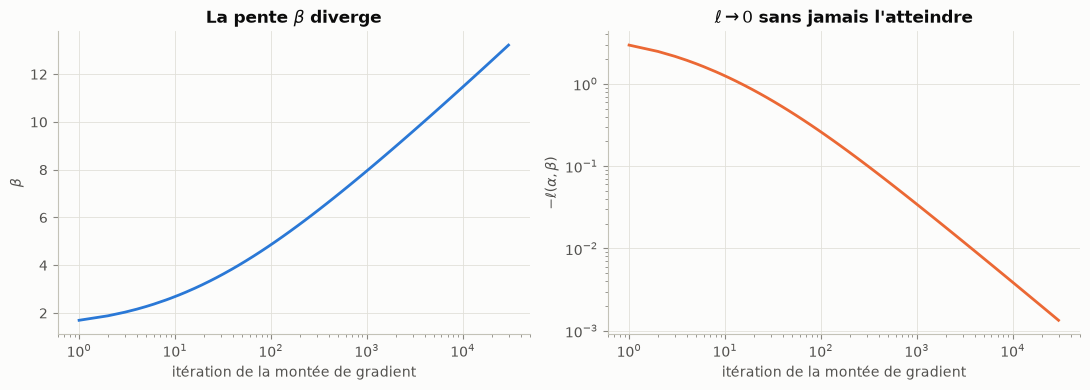

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogx(iters, path[:, 1], color=BLUE)
axes[0].set_xlabel("itération de la montée de gradient")
axes[0].set_ylabel(r"$\beta$")
axes[0].set_title(r"La pente $\beta$ diverge")
axes[1].loglog(iters, -ll, color=ORANGE)
axes[1].set_xlabel("itération de la montée de gradient")
axes[1].set_ylabel(r"$-\ell(\alpha, \beta)$")
axes[1].set_title(r"$\ell \to 0$ sans jamais l'atteindre")
plt.tight_layout()
plt.show()

Visualisons les courbes ajustées $x \mapsto \sigma(\alpha + \beta x)$ à différentes
itérations : elles tendent vers une fonction en escalier.

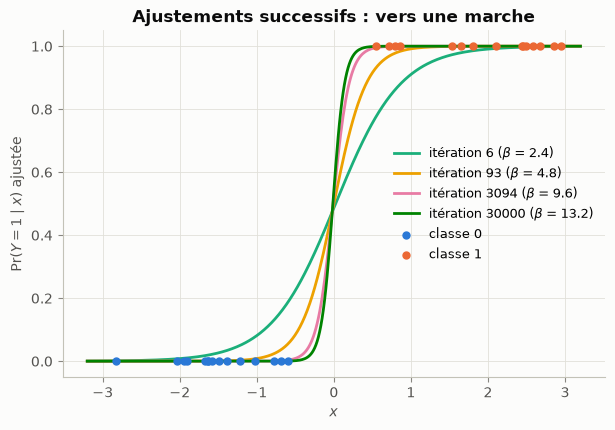

In [5]:
grid = np.linspace(-3.2, 3.2, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
for c, k in zip(COLORS[2:], [5, 20, 40, len(iters) - 1]):
    ax.plot(grid, g18.sigmoid(path[k, 0] + path[k, 1] * grid), color=c,
            label=r"itération %d ($\beta$ = %.1f)" % (iters[k], path[k, 1]))
ax.scatter(x0, np.zeros(15), color=BLUE, label="classe 0", zorder=3)
ax.scatter(x1, np.ones(15), color=ORANGE, label="classe 1", zorder=3)
ax.set_xlabel("$x$")
ax.set_ylabel(r"$\Pr(Y=1 \mid x)$ ajustée")
ax.set_title("Ajustements successifs : vers une marche")
ax.legend(loc="center right")
plt.show()

### Lien avec le chapitre : en grande dimension, tout est séparable

Quand $p \ge N - 1$, $N$ points « génériques » de $\mathbb{R}^p$ sont **toujours**
linéairement séparables, quelles que soient leurs étiquettes : le système
$\alpha + x_i^T\beta = s_i$ ($i = 1, \dots, N$) a $p + 1 \ge N$ inconnues et admet une
solution pour tout second membre, en particulier $s_i = +1$ pour la classe 1 et $-1$
pour la classe 0. L'argument précédent s'applique alors dans la direction $\beta$ trouvée :
la logistique non pénalisée n'a jamais de solution si $p \gg N$. D'où l'usage, dans tout
le chapitre, d'une **pénalité quadratique** $\lambda \|\beta\|^2$ : le critère pénalisé
tend vers $-\infty$ (en vraisemblance pénalisée) quand $\|\beta\| \to \infty$, et le
maximum existe.

In [6]:
N, p = 30, 100
X = rng.randn(N, p)
yrand = rng.randint(0, 2, N)                      # étiquettes purement aléatoires
s = 2.0 * yrand - 1
Xa = np.c_[np.ones(N), X]
w = np.linalg.lstsq(Xa, s, rcond=None)[0]         # solution exacte du système
print("marge minimale y_i * (alpha + x_i^T beta) =", np.min(s * (Xa @ w)).round(6))
for lam in [10.0, 1.0, 0.1, 0.01, 1e-3, 1e-4]:
    b0, b = g18.logistic_ridge(X, yrand, lam)
    print("lambda = %7.0e   ||beta_hat|| = %5.2f" % (lam, np.linalg.norm(b)))

marge minimale y_i * (alpha + x_i^T beta) = 1.0


lambda =   1e+01   ||beta_hat|| =  0.62


lambda =   1e+00   ||beta_hat|| =  1.63


lambda =   1e-01   ||beta_hat|| =  2.82


lambda =   1e-02   ||beta_hat|| =  4.10


lambda =   1e-03   ||beta_hat|| =  5.44


lambda =   1e-04   ||beta_hat|| =  6.81


Avec des étiquettes tirées au hasard, les données sont pourtant parfaitement séparées
(marge $= 1$), et la norme de l'estimateur logistique ridge croît sans borne quand
$\lambda \to 0$ (lentement, à peu près comme $\log(1/\lambda)$, comme la pente de la
montée de gradient ci-dessus).

> **À retenir.** Si les classes sont séparables, $\ell(\alpha, \beta) < 0$ partout mais
> $\sup \ell = 0$ : le maximum n'est pas atteint et $|\hat\beta| = \infty$. Pour $p \ge N-1$
> c'est la règle et non l'exception : il faut régulariser.

## Exercice 18.12 : Validation croisée de la ridge : réduire $X$ une seule fois

**Énoncé (reformulé).** On veut choisir le paramètre ridge $\lambda$ par validation
croisée à 10 blocs, pour un modèle linéaire quelconque à pénalité quadratique, dans une
situation $p \gg N$, en utilisant les raccourcis de calcul de la section 18.3.5.
Montrer qu'il suffit de réduire **une seule fois** la matrice $X$ ($N \times p$) en la
matrice $R$ ($N \times N$), et d'utiliser $R$ dans toutes les étapes de la validation
croisée.

### Rappels : la réduction $X = RV^T$ (éq. (18.12)–(18.13) du livre)

La décomposition en valeurs singulières (SVD) de $X$ s'écrit $X = UDV^T$, avec $U$
($N \times N$) orthogonale, $D$ diagonale ($N \times N$) et $V$ ($p \times N$) à
colonnes orthonormées : $V^TV = I_N$. On pose $R = UD$ ($N \times N$), de sorte que
$X = RV^T$. Ligne par ligne : $x_i = V r_i$, où $r_i^T$ est la $i$-ème ligne de $R$.

Le **théorème (18.16)–(18.17)** dit : pour toute perte $L$ et tout $\lambda > 0$,

$$
\min_{\beta_0, \beta \in \mathbb{R}^p} \sum_{i=1}^N L(y_i, \beta_0 + x_i^T\beta) + \lambda \beta^T\beta
\quad\text{et}\quad
\min_{\theta_0, \theta \in \mathbb{R}^N} \sum_{i=1}^N L(y_i, \theta_0 + r_i^T\theta) + \lambda \theta^T\theta
$$

ont des solutions liées par $\hat\beta_0 = \hat\theta_0$ et $\hat\beta = V\hat\theta$.

### Ce que la preuve du théorème utilise vraiment

Rappelons l'argument (c'est l'objet de l'exercice 18.5). Tout $\beta \in \mathbb{R}^p$ se
décompose en $\beta = V\theta + \beta_\perp$ avec $\theta = V^T\beta$ et
$V^T\beta_\perp = 0$ (projection orthogonale sur l'image de $V$). Alors :

1. $x_i^T\beta = r_i^T V^T V\theta + r_i^T V^T\beta_\perp = r_i^T\theta$, car $V^TV = I$
   et $V^T\beta_\perp = 0$ : **la perte ne dépend que de $\theta$** ;
2. $\beta^T\beta = \theta^T\theta + \|\beta_\perp\|^2$ (Pythagore) : la pénalité est
   minimale pour $\beta_\perp = 0$.

Donc à l'optimum $\beta_\perp = 0$, $\hat\beta = V\hat\theta$, et $\hat\theta$ résout le
problème réduit. **Point clé :** la preuve n'utilise que deux faits,
(i) chaque ligne s'écrit $x_i = Vr_i$ et (ii) $V^TV = I$. Elle n'utilise **pas** le fait
que $R$ et $V$ proviennent de la SVD *de la matrice sur laquelle on ajuste*.

### Solution

Dans la validation croisée, le bloc $k$ sert de test et les autres observations,
d'indices $T_k$, servent à l'apprentissage. La matrice d'apprentissage est la
sous-matrice $X_{T_k}$ formée des lignes $x_i$, $i \in T_k$. Or chacune de ces lignes
vérifie encore $x_i = V r_i$ **avec le même $V$** (calculé une fois sur toutes les
données) :

$$
X_{T_k} = R_{T_k} V^T , \qquad V^TV = I_N .
$$

Les hypothèses (i) et (ii) sont satisfaites : le théorème s'applique au problème
d'apprentissage du bloc $k$, et
$\hat\beta^{(-k)}_0 = \hat\theta^{(-k)}_0$, $\hat\beta^{(-k)} = V\hat\theta^{(-k)}$, où
$\hat\theta^{(-k)}$ est obtenu en ajustant le modèle sur les lignes $r_i$, $i \in T_k$.

Pour une observation test $i$ du bloc $k$, la prédiction vaut

$$
\hat\beta^{(-k)}_0 + x_i^T\hat\beta^{(-k)} = \hat\theta_0^{(-k)} + r_i^T V^TV\hat\theta^{(-k)}
 = \hat\theta_0^{(-k)} + r_i^T\hat\theta^{(-k)} .
$$

Les prédictions sur les blocs test, donc les erreurs de validation croisée pour chaque
$\lambda$, sont **identiques** qu'on travaille avec $X$ ou avec $R$. On calcule la SVD
une seule fois (coût $O(pN^2)$), puis toutes les $10 \times (\text{nombre de }\lambda)$
régressions se font en dimension $N$.

> **Remarque.** Le centrage des variables à l'intérieur de chaque bloc reste compatible :
> la moyenne des $x_i$, $i \in T_k$, vaut $V$ fois la moyenne des $r_i$. En revanche une
> **standardisation** variable par variable recalculée sur chaque bloc (division par des
> écarts-types différents) n'est pas de la forme $x_i \mapsto V r_i$ et casse l'équivalence :
> il faut alors standardiser une fois pour toutes avant la SVD.

### Vérification numérique

On simule $N = 60$ observations et $p = 5000$ variables (seules les 20 premières sont
utiles), puis on calcule la courbe de validation croisée à 10 blocs de la ridge avec
$X$ puis avec $R$.

In [7]:
rng = np.random.RandomState(0)
N, p = 60, 5000
X = rng.randn(N, p)
beta_true = np.r_[np.full(20, 0.5), np.zeros(p - 20)]
y = X @ beta_true + rng.randn(N)
folds = g18.kfold_indices(N, 10, rng)
lams = np.logspace(0, 5, 30)

In [8]:
t = time.time()
R, V = g18.svd_reduce(X)                     # une seule réduction
cv_R = g18.ridge_cv_errors(R, y, lams, folds)
t_R = time.time() - t
t = time.time()
cv_X = g18.ridge_cv_errors(X, y, lams, folds)
t_X = time.time() - t
print("taille de R :", R.shape, " écart max entre les deux courbes : %.2e"
      % np.max(np.abs(cv_R - cv_X)))
print("temps avec X : %.2fs   avec R (SVD comprise) : %.2fs" % (t_X, t_R))

taille de R : (60, 60)  écart max entre les deux courbes : 3.55e-15
temps avec X : 0.16s   avec R (SVD comprise) : 0.35s


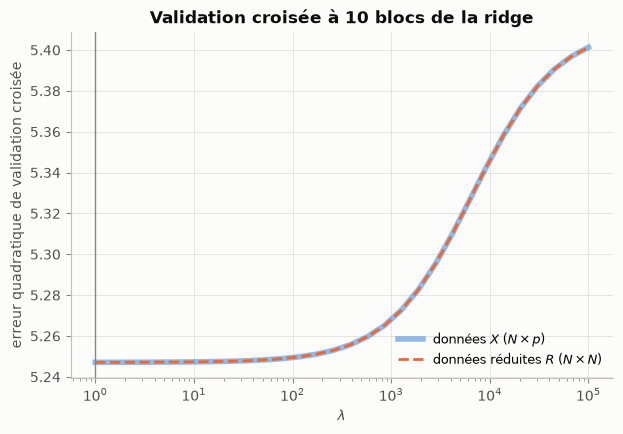

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(lams, cv_X, color=BLUE, lw=4, alpha=0.5, label="données $X$ ($N\\times p$)")
ax.semilogx(lams, cv_R, color=ORANGE, ls="--", label="données réduites $R$ ($N\\times N$)")
ax.axvline(lams[np.argmin(cv_R)], color=GRAY, lw=1)
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel("erreur quadratique de validation croisée")
ax.set_title("Validation croisée à 10 blocs de la ridge")
ax.legend()
plt.show()

Les deux courbes sont confondues (à la précision machine près). Ici la ridge est déjà
codée sous forme « duale » (coût $O(N^2p)$ par ajustement) et le calcul de la SVD
domine : il n'y a pas de gain de temps notable. Pour une méthode qui doit inverser une matrice $p\times p$ (Newton pour la
logistique, par exemple) le gain serait de l'ordre de $(p/N)^3$.

> **À retenir.** La réduction $X = RV^T$ ne dépend pas des observations retenues : toute
> sous-matrice de lignes s'écrit $X_T = R_TV^T$ avec le même $V$. On calcule donc $R$ une
> fois, et la validation croisée se fait entièrement sur $R$.

## Exercice 18.13 : Logistique ridge à partir des produits scalaires

**Énoncé (reformulé).** Les $p > N$ prédicteurs ne sont connus qu'à travers la matrice
$N \times N$ des produits scalaires $K = XX^T$. On veut ajuster l'équivalent d'une
régression logistique linéaire dans les variables d'origine, avec pénalité quadratique,
et prédire avec des produits scalaires : un nouveau point $x_0$ est présenté sous la
forme $k_0 = Xx_0$ (ses produits scalaires avec les $x_i$). Soit $K = UD^2U^T$ la
décomposition spectrale de $K$. Montrer que les prédictions s'écrivent
$\hat f_0 = k_0^T\hat\alpha$ avec

(a) $\hat\alpha = UD^{-1}\hat\beta$, et

(b) $\hat\beta$ l'estimateur de la logistique ridge avec matrice d'entrée $R = UD$.

Expliquer pourquoi la même approche vaut pour toute matrice de noyau $K$ adaptée.

### Rappels

- La logistique ridge de l'éq. (18.16) minimise
  $-\sum_i \big[y_i\eta_i - \log(1 + e^{\eta_i})\big] + \lambda\beta^T\beta$ avec
  $\eta_i = \beta_0 + x_i^T\beta$ (l'ordonnée à l'origine n'est pas pénalisée ; elle
  s'ajoute simplement à $k_0^T\hat\alpha$ dans la prédiction).
- Si $X = UDV^T$ (SVD), alors $K = XX^T = UDV^TVDU^T = UD^2U^T$ car $V^TV = I$ :
  **la décomposition spectrale de $K$ fournit $U$ et $D$ sans connaître $X$**.
- On suppose $X$ de rang $N$ (cas générique quand $p > N$), de sorte que $D$ est
  inversible.

### Solution

**Étape 1 : $R$ est calculable à partir de $K$.** Avec $R = UD$, on a $X = RV^T$ et
$RR^T = UD^2U^T = K$. Les lignes $r_i$ de $R$ sont donc obtenues par la seule
diagonalisation de $K$.

**Étape 2 : on applique le théorème (18.16)–(18.17).** La perte logistique est une perte
$L(y_i, \beta_0 + x_i^T\beta)$ avec pénalité quadratique ; le théorème donne
$\hat\beta_0^{(X)} = \hat\theta_0$ et $\hat\beta^{(X)} = V\hat\beta$, où
$(\hat\theta_0, \hat\beta)$ est la logistique ridge ajustée sur les lignes de $R$
(c'est le point (b)).

**Étape 3 : on exprime $V$ avec $K$.** De $X = UDV^T$ on tire, en multipliant à gauche
par $U^T$ puis par $D^{-1}$ : $V^T = D^{-1}U^TX$, soit $V = X^TUD^{-1}$.

**Étape 4 : la prédiction.** Pour un nouveau point,

$$
\hat f_0 = \hat\theta_0 + x_0^T\hat\beta^{(X)} = \hat\theta_0 + x_0^TX^TUD^{-1}\hat\beta
 = \hat\theta_0 + (Xx_0)^T\,UD^{-1}\hat\beta = \hat\theta_0 + k_0^T\hat\alpha ,
$$

avec $\hat\alpha = UD^{-1}\hat\beta$ (point (a)). En dehors de l'ordonnée à l'origine,
on a bien $\hat f_0 = k_0^T\hat\alpha$.

### Généralisation à un noyau quelconque

Rien dans le calcul n'utilise la forme particulière $K = XX^T$ ; on a seulement besoin
que $K$ soit une matrice **symétrique semi-définie positive** de produits scalaires
$K_{ii'} = \langle h(x_i), h(x_{i'})\rangle$ pour une certaine transformation $h$ des
variables (éventuellement en dimension infinie), et que $k_0$ contienne les
$\langle h(x_0), h(x_i)\rangle$. C'est le cas pour un noyau de Mercer
$K(x, x')$ (polynomial, gaussien…, voir section 12.3.3 du livre). On remplace
formellement $X$ par la matrice des $h(x_i)$ : $K = UD^2U^T$, $R = UD$, on ajuste la
logistique ridge sur $R$, et $\hat f_0 = \hat\theta_0 + k_0^T UD^{-1}\hat\beta$.
Si $K$ a des valeurs propres nulles, on ne garde que les valeurs propres strictement
positives (la projection de $\hat\beta^{(X)}$ sur le noyau de $X$ est nulle de toute
façon).

### Vérification numérique (noyau linéaire)

On compare la logistique ridge ajustée **directement** sur $X$ ($N = 40$, $p = 300$,
Newton en dimension $301$) à la version par noyau (fonction `kernel_logistic_ridge`) qui
ne voit que $K$ et $k_0$.

In [10]:
rng = np.random.RandomState(0)
N, p, lam = 40, 300, 1.0
X = rng.randn(N, p)
y = (X[:, :5].sum(axis=1) + rng.randn(N) > 0).astype(int)
X0 = rng.randn(200, p)

b0, b = g18.logistic_ridge(X, y, lam)                 # primal, dimension p
theta0, alpha = g18.kernel_logistic_ridge(X @ X.T, y, lam)   # seulement K
f_primal = b0 + X0 @ b
f_kernel = theta0 + (X0 @ X.T) @ alpha                # k0 = X x0 pour chaque x0
print("écart max des prédictions : %.2e" % np.max(np.abs(f_primal - f_kernel)))
print("écart sur beta via beta = X^T alpha : %.2e" % np.max(np.abs(b - X.T @ alpha)))

écart max des prédictions : 6.00e-15
écart sur beta via beta = X^T alpha : 2.98e-16


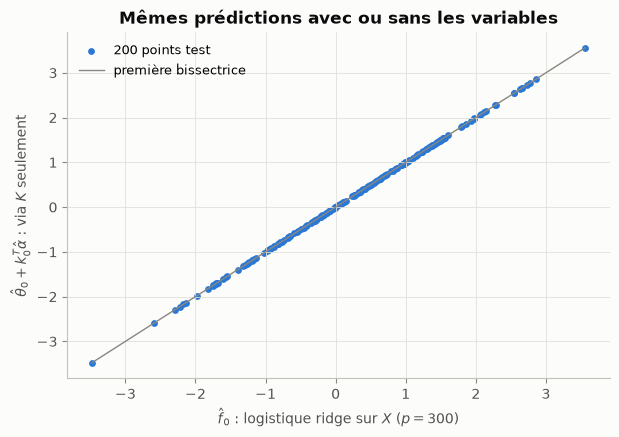

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(f_primal, f_kernel, s=15, color=BLUE, label="200 points test")
lim = [f_primal.min(), f_primal.max()]
ax.plot(lim, lim, color=GRAY, lw=1, label="première bissectrice")
ax.set_xlabel(r"$\hat f_0$ : logistique ridge sur $X$ ($p = 300$)")
ax.set_ylabel(r"$\hat\theta_0 + k_0^T\hat\alpha$ : via $K$ seulement")
ax.set_title("Mêmes prédictions avec ou sans les variables")
ax.legend()
plt.show()

### Avec un noyau gaussien

On applique la même méthode avec $K(x, x') = \exp(-\gamma\|x - x'\|^2)$ à un problème
en dimension 2 dont la frontière est un cercle, ce qu'aucune logistique linéaire ne peut
reproduire.

In [12]:
rng = np.random.RandomState(1)
Xc = rng.uniform(-2, 2, size=(150, 2))
yc = (np.sum(Xc ** 2, axis=1) + 0.4 * rng.randn(150) < 1.8).astype(int)
gamma = 1.0
t0c, alc = g18.kernel_logistic_ridge(g18.rbf_kernel(Xc, Xc, gamma), yc, lam=0.05)
from esl.plotting import decision_grid
xx, yy, G = decision_grid((-2, 2), (-2, 2), n=150)
fG = t0c + g18.rbf_kernel(G, Xc, gamma) @ alc
print("taux d'erreur d'apprentissage :",
      np.mean((t0c + g18.rbf_kernel(Xc, Xc, gamma) @ alc > 0) != yc).round(3))

taux d'erreur d'apprentissage : 0.053


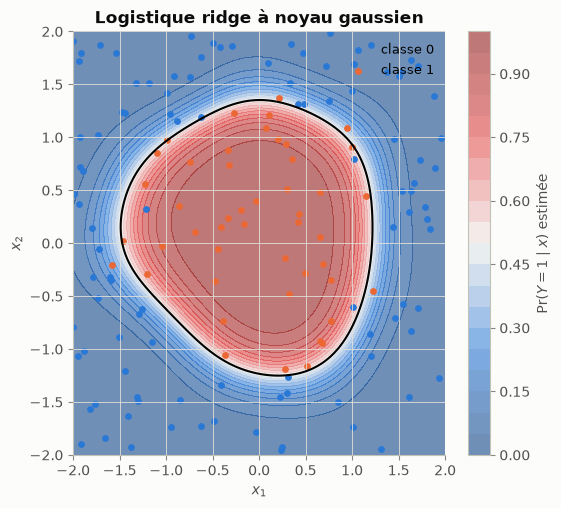

In [13]:
fig, ax = plt.subplots(figsize=(6, 5.5))
cs = ax.contourf(xx, yy, g18.sigmoid(fG).reshape(xx.shape), levels=20, cmap=DIV, alpha=0.6)
ax.contour(xx, yy, fG.reshape(xx.shape), levels=[0], colors="k", linewidths=1.5)
ax.scatter(*Xc[yc == 0].T, color=BLUE, s=15, label="classe 0")
ax.scatter(*Xc[yc == 1].T, color=ORANGE, s=15, label="classe 1")
plt.colorbar(cs, ax=ax, label=r"$\Pr(Y=1\mid x)$ estimée")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_title("Logistique ridge à noyau gaussien")
ax.legend(loc="upper right")
plt.show()

> **À retenir.** Toute régression à pénalité quadratique peut être ajustée à partir des
> seuls produits scalaires : $K = UD^2U^T$, régression sur $R = UD$, puis
> $\hat\alpha = UD^{-1}\hat\beta$ et $\hat f_0 = k_0^T\hat\alpha$ (plus l'ordonnée à l'origine).
> Remplacer $XX^T$ par un noyau donne gratuitement une version non linéaire.

## Exercice 18.14 : 1-plus-proche-voisin pondéré par les distances

**Énoncé (reformulé).** On considère le classifieur du plus proche voisin (section 13.3)
pour deux classes $\pm 1$. Soit $d_+(x_0)$ la plus petite distance de $x_0$ à une
observation d'apprentissage de la classe $+1$, et $d_-(x_0)$ l'analogue pour la classe
$-1$. On note $N_+$, $N_-$ les effectifs des classes et $N = N_+ + N_-$.

(a) Montrer que
$$\delta(x_0) = \log\frac{d_-(x_0)}{d_+(x_0)} \qquad\text{(éq. (18.57) du livre)}$$
peut être vu comme une fonction discriminante non paramétrique associée au 1-ppv.
*Indication :* montrer que $\hat f_+(x_0) = \dfrac{1}{N_+ d_+(x_0)}$ peut être vu comme
une estimation non paramétrique de la densité de la classe $+1$ en $x_0$.

(b) Comment modifier cette fonction pour utiliser des probabilités a priori $\pi_+$,
$\pi_-$ différentes des proportions observées $N_+/N$, $N_-/N$ ?

(c) Comment généraliser à la classification par $K$ plus proches voisins ?

### Rappels : densité estimée par les plus proches voisins

Si $f$ est une densité continue et $B$ une petite boule centrée en $x_0$, de volume
$\operatorname{vol}(B)$, la probabilité qu'une observation tombe dans $B$ vaut
$\int_B f \approx f(x_0)\operatorname{vol}(B)$. Avec un échantillon de taille $n$, le
nombre attendu de points dans $B$ est donc $\approx n f(x_0)\operatorname{vol}(B)$.
**Estimateur des plus proches voisins :** on prend pour $B$ la plus petite boule centrée
en $x_0$ contenant $k$ points de l'échantillon, de rayon $d^{(k)}(x_0)$ (distance au
$k$-ième plus proche voisin), et on égalise :

$$
k \approx n\,\hat f(x_0)\,c_p\,[d^{(k)}(x_0)]^p
\quad\Longrightarrow\quad
\hat f(x_0) = \frac{k}{n\,c_p\,[d^{(k)}(x_0)]^p},
$$

où $c_p\,r^p$ est le volume de la boule de rayon $r$ dans $\mathbb{R}^p$ ($c_1 = 2$,
$c_2 = \pi$…).

### (a) Le score $\delta$ comme discriminant

Appliquons l'estimateur avec $k = 1$ à chaque classe séparément. Pour la classe $+1$
($n = N_+$, rayon $d_+(x_0)$) et en dimension $p = 1$ (c'est la convention de
l'indication ; on discute $p$ quelconque plus bas) :

$$
\hat f_+(x_0) = \frac{1}{2N_+d_+(x_0)} \propto \frac{1}{N_+d_+(x_0)}, \qquad
\hat f_-(x_0) \propto \frac{1}{N_-d_-(x_0)} ,
$$

avec la même constante de proportionnalité. La règle de Bayes (chapitre 4) classe en
$+1$ si $\pi_+ f_+(x_0) > \pi_- f_-(x_0)$, c'est-à-dire si le **log-rapport a posteriori**

$$
\log\frac{\pi_+\hat f_+(x_0)}{\pi_-\hat f_-(x_0)}
= \log\frac{\pi_+}{\pi_-} + \log\frac{N_-}{N_+} + \log\frac{d_-(x_0)}{d_+(x_0)}
$$

est positif. Avec les a priori empiriques $\pi_\pm = N_\pm/N$, les deux premiers termes
se compensent exactement : $\log\frac{N_+}{N_-} + \log\frac{N_-}{N_+} = 0$. Il reste

$$
\delta(x_0) = \log\frac{d_-(x_0)}{d_+(x_0)} .
$$

Enfin, $\delta(x_0) > 0 \iff d_+(x_0) < d_-(x_0) \iff$ le plus proche voisin de $x_0$ est
dans la classe $+1$ : le signe de $\delta$ redonne **exactement** la règle du 1-ppv, mais
$\delta$ fournit en plus un **score continu** (utile pour tracer une courbe ROC, comme
dans la figure 18.9 du livre).

> **Remarque (dimension $p$).** En dimension $p$, $\hat f_\pm \propto 1/(N_\pm d_\pm^p)$
> et le log-rapport devient $p\log(d_-/d_+)$ : c'est $\delta$ multiplié par la constante
> $p > 0$. La règle de classement (signe) et la courbe ROC (qui ne dépend que de l'ordre
> des scores) sont inchangées. L'exposant $p$ n'importe que lorsqu'on ajoute un terme
> d'a priori, comme en (b).

### (b) Probabilités a priori quelconques

Il suffit de ne plus simplifier les a priori dans le log-rapport ci-dessus :

$$
\delta_\pi(x_0) = \log\frac{d_-(x_0)}{d_+(x_0)} + \log\frac{\pi_+N_-}{\pi_-N_+}
\qquad\Big(\text{ou } p\log\frac{d_-}{d_+} + \log\frac{\pi_+N_-}{\pi_-N_+}\text{ en dimension } p\Big).
$$

On classe en $+1$ si $\delta_\pi(x_0) > 0$ : le seuil sur $\delta$ est simplement
décalé de $-\log\frac{\pi_+N_-}{\pi_-N_+}$. Si $\pi_+$ est plus grand que la proportion
observée $N_+/N$, le décalage favorise la classe $+1$.

### (c) Généralisation aux $K$ plus proches voisins

On utilise l'estimateur de densité avec $k = K$ dans chaque classe :
$\hat f_\pm(x_0) = K/(N_\pm c_p [d_\pm^{(K)}(x_0)]^p)$, où $d_\pm^{(K)}(x_0)$ est la
distance au $K$-ième plus proche voisin **de la classe $\pm 1$**. Les constantes $K$ et
$c_p$ se simplifient dans le rapport et

$$
\delta_K(x_0) = p\log\frac{d_-^{(K)}(x_0)}{d_+^{(K)}(x_0)} + \log\frac{\pi_+N_-}{\pi_-N_+}.
$$

Avec $K$ plus grand, l'estimation de densité est moins variable (et plus biaisée) : on
retrouve le compromis biais–variance habituel des $K$-ppv. Une autre généralisation,
plus proche du vote majoritaire, serait d'utiliser une moyenne des distances aux $K$
plus proches voisins de chaque classe.

### Illustration : courbes ROC en grande dimension

On simule deux classes gaussiennes en dimension $p = 200$ dont les moyennes ne
diffèrent que sur 10 coordonnées, avec $N_+ = 30$ et $N_- = 60$ (fonction
`dw_knn_score`). On compare les scores pour $K = 1, 5, 15$ sur un grand échantillon test.

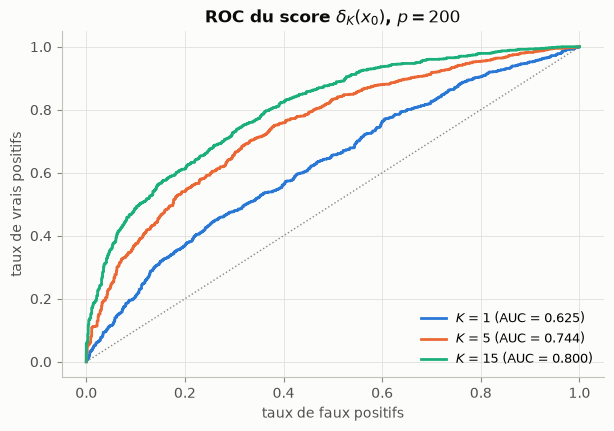

In [14]:
rng = np.random.RandomState(0)
p, Np, Nm = 200, 30, 60
mu = np.r_[np.full(10, 0.8), np.zeros(p - 10)]
Xtr = np.r_[rng.randn(Np, p) + mu, rng.randn(Nm, p)]
ytr = np.r_[np.ones(Np), -np.ones(Nm)].astype(int)
Xte = np.r_[rng.randn(1000, p) + mu, rng.randn(1000, p)]
yte = np.r_[np.ones(1000), -np.ones(1000)].astype(int)

fig, ax = plt.subplots(figsize=(7, 4.5))
for c, k in zip(COLORS, [1, 5, 15]):
    sc = g18.dw_knn_score(Xtr, ytr, Xte, k=k)
    fpr, tpr, auc = g18.roc_curve(sc, yte == 1)
    ax.plot(fpr, tpr, color=c, label="$K$ = %d (AUC = %.3f)" % (k, auc))
ax.plot([0, 1], [0, 1], color=GRAY, lw=1, ls=":")
ax.set_xlabel("taux de faux positifs")
ax.set_ylabel("taux de vrais positifs")
ax.set_title(r"ROC du score $\delta_K(x_0)$, $p = 200$")
ax.legend(loc="lower right")
plt.show()

Vérifions numériquement que le signe de $\delta$ (pour $K = 1$) coïncide avec la règle du
1-ppv, et voyons l'effet d'un a priori (b) : on suppose que dans la population cible les
deux classes sont équiprobables ($\pi_+ = \pi_- = 1/2$) alors que l'échantillon
d'apprentissage en contient deux fois moins de $+1$.

In [15]:
D = g18.pairwise_dist(Xte, Xtr)
pred_1nn = ytr[np.argmin(D, axis=1)]
d1 = g18.dw_knn_score(Xtr, ytr, Xte, k=1)
print("accord signe(delta) / 1-ppv :", np.mean(np.sign(d1) == pred_1nn))
for dim in [1, p]:
    sp = g18.dw_knn_score(Xtr, ytr, Xte, k=1, priors=(0.5, 0.5), dim=dim)
    print("exposant %3d : proportion classée +1 = %.3f (sans a priori : %.3f)"
          % (dim, np.mean(sp > 0), np.mean(d1 > 0)))

accord signe(delta) / 1-ppv : 1.0
exposant   1 : proportion classée +1 = 1.000 (sans a priori : 0.251)
exposant 200 : proportion classée +1 = 0.294 (sans a priori : 0.251)


Avec l'exposant $1$ de l'indication, le terme $\log(N_-/N_+) = \log 2$ pèse beaucoup :
tous les points test sont classés $+1$. Avec l'exposant $p = 200$ (la « vraie » dimension), le
terme de distance domine et la correction est bien plus douce. En grande dimension les
distances sont toutes du même ordre (concentration de la mesure), d'où cette
sensibilité : la **forme** du score compte dès qu'on le combine à un a priori.

> **À retenir.** $\delta(x_0) = \log(d_-/d_+)$ est le log-rapport des estimateurs « plus
> proche voisin » des densités de classe, avec a priori empiriques : son signe est la
> règle du 1-ppv. Des a priori $\pi_\pm$ ajoutent la constante $\log(\pi_+N_-/\pi_-N_+)$ ;
> les $K$-ppv utilisent la distance au $K$-ième voisin de chaque classe.

## Exercice 18.15 : ACP à noyau : projeter un nouveau point

**Énoncé (reformulé).** La section 18.5.2 calcule les variables principales $Z$ à partir
d'une matrice de produits scalaires **non centrée** $K$ : on diagonalise
$(I - M)K(I - M) = UD^2U^T$ avec $M = \mathbf{1}\mathbf{1}^T/N$, puis $Z = UD$. Soit
$k_0$ le vecteur des $N$ produits scalaires entre un nouveau point $x_0$ et les $x_i$
d'apprentissage. Montrer que les projections (centrées) de $x_0$ sur les directions
principales sont

$$
z_0 = D^{-1}U^T(I - M)\big[k_0 - K\mathbf{1}/N\big]. \qquad\text{(éq. (18.58) du livre)}
$$

### Rappels

- $M = \frac{1}{N}\mathbf{1}\mathbf{1}^T$ est l'**opérateur de moyenne** : pour un
  vecteur $v \in \mathbb{R}^N$, $Mv$ est le vecteur constant égal à la moyenne des
  $v_i$, et $(I - M)v$ est $v$ recentré. $M$ et $I - M$ sont des projecteurs
  orthogonaux (symétriques, idempotents).
- $\tilde X = (I - M)X$ est la matrice centrée : ses lignes sont $x_i - \bar x$, avec
  $\bar x = X^T\mathbf{1}/N$.
- ACP (section 14.5.1) : si $\tilde X = UDV^T$ (SVD), les directions principales sont
  les colonnes de $V$, et la projection centrée d'un point $x$ est $V^T(x - \bar x)$ ;
  pour les points d'apprentissage cela donne $\tilde XV = UD = Z$.

### Solution

**Étape 1 : $U$ et $D$ viennent de $\tilde X$.** On a
$(I - M)K(I - M) = (I - M)XX^T(I - M)^T = \tilde X\tilde X^T = UDV^TVDU^T = UD^2U^T$
(on a utilisé la symétrie de $I - M$ et $V^TV = I$). La décomposition spectrale de la
matrice doublement centrée fournit donc les $U$ et $D$ de la SVD de $\tilde X$.

**Étape 2 : exprimer $V$.** De $\tilde X = UDV^T$ on tire $V^T = D^{-1}U^T\tilde X$
(en ne gardant que les valeurs singulières non nulles, pour que $D$ soit inversible).

**Étape 3 : projeter $x_0$.**

$$
z_0 = V^T(x_0 - \bar x) = D^{-1}U^T\tilde X(x_0 - \bar x) = D^{-1}U^T(I - M)X(x_0 - \bar x).
$$

**Étape 4 : tout écrire avec des produits scalaires.** $Xx_0 = k_0$ (la $i$-ème
coordonnée est $\langle x_i, x_0\rangle$), et
$X\bar x = XX^T\mathbf{1}/N = K\mathbf{1}/N$. Donc

$$
z_0 = D^{-1}U^T(I - M)\big[k_0 - K\mathbf{1}/N\big]. \qquad\blacksquare
$$

> **Remarque.** Le vecteur $(I - M)[k_0 - K\mathbf{1}/N]$ est exactement le vecteur des
> produits scalaires **centrés** $\langle x_i - \bar x, x_0 - \bar x\rangle$ : on a retiré
> la moyenne côté $x_0$ (terme $K\mathbf{1}/N$) et côté $x_i$ (opérateur $I - M$).
> Vérification : si $x_0 = x_j$ est un point d'apprentissage, $k_0$ est la $j$-ème colonne
> de $K$, le vecteur obtenu est la $j$-ème colonne de $\tilde X\tilde X^T = UD^2U^T$, et
> $z_0 = D^{-1}U^TUD^2U^Te_j = DU^Te_j$ : c'est bien la $j$-ème ligne de $Z = UD$.
> Comme précédemment, la formule reste valable pour un noyau quelconque (ACP à noyau,
> section 14.5.4).

### Vérification numérique (noyau linéaire)

On compare la formule (18.58), qui n'utilise que $K$ et $k_0$, à l'ACP « classique »
calculée sur la matrice $X$ centrée (signes des axes alignés, car un vecteur propre
n'est défini qu'au signe près).

In [16]:
rng = np.random.RandomState(0)
N, p = 50, 400
Xk = rng.randn(N, p) @ np.diag(np.linspace(3, 0.2, p)) + 5.0   # non centrée
X0 = rng.randn(10, p) @ np.diag(np.linspace(3, 0.2, p)) + 5.0
K = Xk @ Xk.T
U, d, Z = g18.kernel_pca(K, n_components=3)
z0 = g18.kernel_pca_project(K, U, d, Xk @ X0.T).T     # (10, 3)

xbar = Xk.mean(axis=0)
_, _, Vt = np.linalg.svd(Xk - xbar, full_matrices=False)
z0_lin = (X0 - xbar) @ Vt[:3].T
sign = np.sign(np.sum(Z * ((Xk - xbar) @ Vt[:3].T), axis=0))
print("écart max (formule 18.58 vs ACP sur X) : %.2e" % np.max(np.abs(z0 * sign - z0_lin)))

écart max (formule 18.58 vs ACP sur X) : 3.96e-13


### Illustration avec un noyau gaussien

Deux cercles concentriques ne sont pas séparés par l'ACP linéaire ; avec un noyau
gaussien, la première composante principale les sépare. On ajuste l'ACP à noyau sur
200 points, puis on projette 200 **nouveaux** points avec (18.58).

In [17]:
def cercles(n, rng):
    lab = rng.randint(0, 2, n)
    r = np.where(lab == 1, 1.0, 0.35) + 0.08 * rng.randn(n)
    a = rng.uniform(0, 2 * np.pi, n)
    return np.c_[r * np.cos(a), r * np.sin(a)], lab

rng = np.random.RandomState(2)
Xa, la = cercles(200, rng)
Xb, lb = cercles(200, rng)
gamma = 5.0
Ka = g18.rbf_kernel(Xa, Xa, gamma)
Ua, da, Za = g18.kernel_pca(Ka, n_components=2)
zb = g18.kernel_pca_project(Ka, Ua, da, g18.rbf_kernel(Xa, Xb, gamma)).T

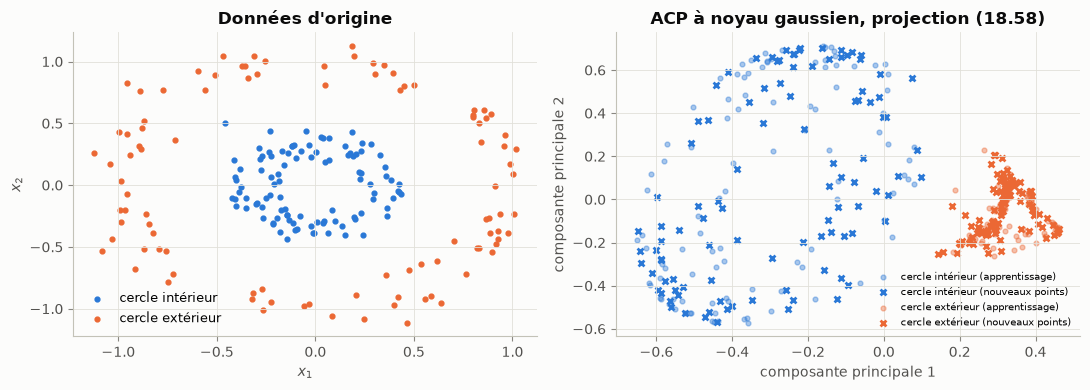

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for lab, c, nom in [(0, BLUE, "cercle intérieur"), (1, ORANGE, "cercle extérieur")]:
    axes[0].scatter(*Xa[la == lab].T, color=c, s=12, label=nom)
    axes[1].scatter(*Za[la == lab].T, color=c, s=12, alpha=0.4,
                    label=nom + " (apprentissage)")
    axes[1].scatter(*zb[lb == lab].T, color=c, s=18, marker="x",
                    label=nom + " (nouveaux points)")
axes[0].set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
axes[0].set_title("Données d'origine")
axes[0].legend()
axes[1].set_xlabel("composante principale 1")
axes[1].set_ylabel("composante principale 2")
axes[1].set_title("ACP à noyau gaussien, projection (18.58)")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

Les nouveaux points (croix) se placent exactement dans les nuages des points
d'apprentissage de leur classe, et la première composante sépare les deux cercles.
Comparons enfin avec `sklearn.decomposition.KernelPCA` (implémentation de référence,
utilisée seulement pour contrôle).